In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import rioxarray as rxr
import seaborn as sns
import xarray as xr
from src.data_processing.load_data import ClimateModelData
from src.data_processing.test_climate_data import (
    has_duplicate_coords,
    has_identical_random_timesteps,
    is_time_sorted,
)
from src.utils.cdo_commands import cdo_remap, save_cdo_griddes
from src.utils.constants import EXTENT_BC, EXTENT_BC_MRRO, EXTENT_CH
from src.utils.utils_xarray import sel_extent

In [3]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])

In [4]:
dask.config.set(num_workers=10)
dask.config.set({"array.chunk-size": "500MiB"})

# CERRA

In [95]:
xr.open_dataset("/net/atmos/data/cerra/original/2t/2t_3hr_cerra_1984.nc")

<xarray.Dataset> Size: 4GB
Dimensions:            (time: 976, x: 1069, y: 1069, height: 1)
Coordinates:
  * time               (time) datetime64[ns] 8kB 1984-09-01 ... 1984-12-31T21...
  * x                  (x) float64 9kB 0.0 5.5e+03 ... 5.868e+06 5.874e+06
  * y                  (y) float64 9kB 0.0 5.5e+03 ... 5.868e+06 5.874e+06
  * height             (height) float64 8B 2.0
Data variables:
    Lambert_Conformal  int32 4B ...
    2t                 (time, height, y, x) float32 4GB ...
Attributes:
    CDI:          Climate Data Interface version 1.9.10 (https://mpimet.mpg.d...
    Conventions:  CF-1.6
    history:      Thu Jan 12 15:56:16 2023: cdo -f nc copy /net/atmos/data/ce...
    CDO:          Climate Data Operators version 1.9.10 (https://mpimet.mpg.d...

In [ ]:
ds_2t_cerra = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cerra_processed/regridded/2t.zarr", chunks="auto"
)

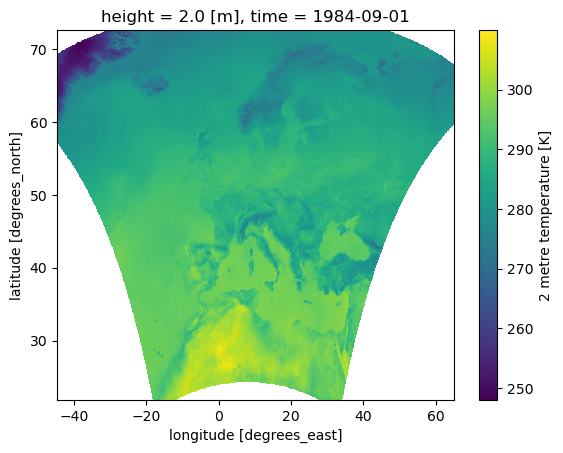

In [5]:
ds_2t_cerra["2t"].isel(time=0).plot()

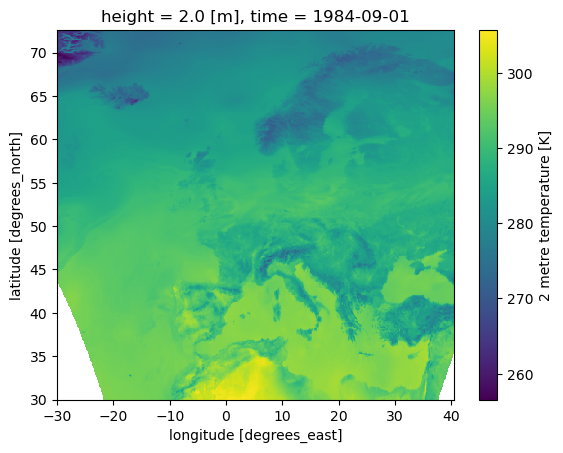

In [19]:
sel_extent(ds_2t_cerra["2t"].isel(time=0), extent=EXTENT_BC).plot()

# CNRM

In [4]:
path_tas_cnrm = Path(
    "/net/atmos/data/cordex/EUR-11/rcp85/3hr/tas/CNRM/CNRM-CERFACS-CNRM-CM5/CNRM-ALADIN63/r1i1p1/"
)
ds_tas_cnrm = xr.open_dataset(sorted(path_tas_cnrm.glob("*.nc"))[0], chunks="auto")

In [ ]:
# ds_tas_cnrm.Lambert_Conformal.attrs = {
#     "grid_mapping_name": "lambert_conformal_conic",
#     "latitude_of_projection_origin": 49.5,
#     "standard_parallel": 49.5,
#     "longitude_of_central_meridian": 10.5,
#     "false_easting": 2925000.,
#     "false_northing": 2925000.,
#     "earth_radius": 6371229.
# }
# ds_tas_cnrm.to_netcdf(sorted(path_tas_cnrm.glob("*.nc"))[0].name)

In [10]:
ds_tas_cnrm

<xarray.Dataset> Size: 2GB
Dimensions:            (time: 2920, y: 453, x: 453, nvertex: 4)
Coordinates:
  * time               (time) datetime64[ns] 23kB 2006-01-01T03:00:00 ... 200...
    lon                (y, x) float64 2MB dask.array<chunksize=(453, 453), meta=np.ndarray>
    lat                (y, x) float64 2MB dask.array<chunksize=(453, 453), meta=np.ndarray>
  * x                  (x) float64 4kB 0.0 12.5 25.0 ... 5.638e+03 5.65e+03
  * y                  (y) float64 4kB 0.0 12.5 25.0 ... 5.638e+03 5.65e+03
    height             float64 8B ...
Dimensions without coordinates: nvertex
Data variables:
    tas                (time, y, x) float32 2GB dask.array<chunksize=(163, 453, 453), meta=np.ndarray>
    Lambert_Conformal  |S1 1B ...
    bounds_lon         (y, x, nvertex) float64 7MB dask.array<chunksize=(453, 453, 4), meta=np.ndarray>
    bounds_lat         (y, x, nvertex) float64 7MB dask.array<chunksize=(453, 453, 4), meta=np.ndarray>
Attributes: (12/26)
    description:                    Created by xios
    title:                          Created by xios
    Conventions:                    CF-1.6
    creation_date:                  2018-11-19T14:32:37Z
    tracking_id:                    hdl:21.14103/f5119218-5dd1-4065-98c7-805c...
    name:                           EUR-11_CNRM-CERFACS-CNRM-CM5_rcp85_r1i1p1...
    ...                             ...
    CORDEX_domain:                  EUR-11
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    comment:                        CORDEX Europe EUR-11 CNRM-ALADIN 6.3 L91 ...
    c3s_disclaimer:                 This data has been produced in the contex...
    driving_experiment_comment:     Known issue correction: this simulation (...
    frequency:                      3hr

In [5]:
cdo_remap(
    sorted(path_tas_cnrm.glob("*.nc"))[0],
    str(Path.cwd() / f"{sorted(path_tas_cnrm.glob('*.nc'))[0].stem}_con.nc"),
    "conservative",
    path_data_processed / "climate_grids" / "grid_EUR11_lonlat_griddes.txt",
    path_data_processed / "climate_grids" / "grid_cnrm_453x453.txt"
)

cdo    remapcon: YAC first order conservative weights from curvilinear (453x453) to lonlat (1096x507) grid


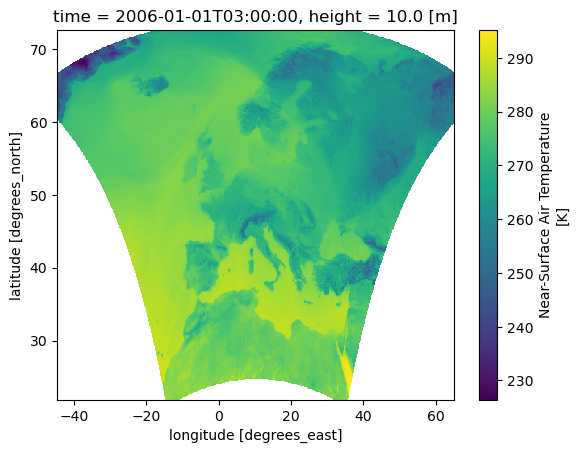

In [6]:
xr.open_dataset(
    str(Path.cwd() / f"{sorted(path_tas_cnrm.glob('*.nc'))[0].stem}_con.nc")
).tas.isel(time=0).plot()

In [47]:
cdo_remap(
    str(sorted(path_tas_cnrm.glob("*.nc"))[0]),
    str(Path.cwd() / sorted(path_tas_cnrm.glob("*.nc"))[0].name),
    "bilinear",
    path_data_processed / "climate_grids" / "grid_EUR11_lonlat_griddes.txt",
)

cdo    remapbil: Bilinear weights from curvilinear (453x453) to lonlat (1096x507) grid


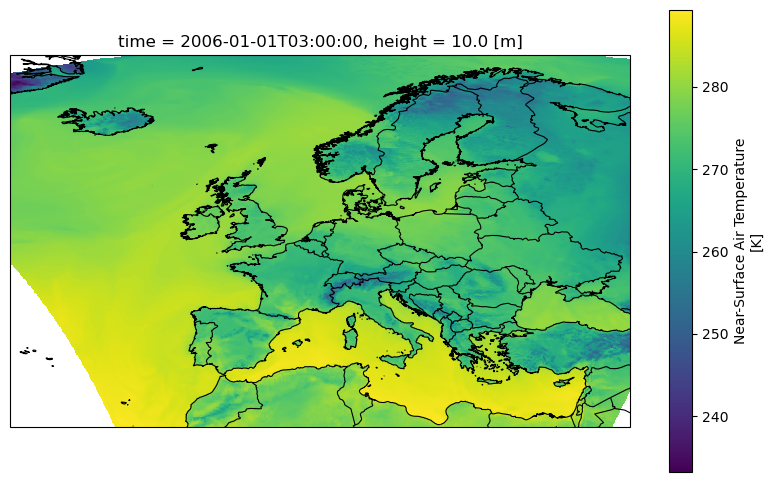

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
data = sel_extent(
    xr.open_dataset(Path.cwd() / sorted(path_tas_cnrm.glob("*.nc"))[0].name).tas.isel(
        time=0
    ),
    extent=EXTENT_BC,
)
data.plot(ax=ax, transform=ccrs.PlateCarree())
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

In [ ]:
xr.open_dataset(Path.cwd() / sorted(path_tas_cnrm.glob("*.nc"))[0].name).tas.isel(
    time=0
).plot()

In [ ]:
save_cdo_griddes(sorted(path_tas_cnrm.glob("*.nc"))[0], Path.cwd() / "grid_cnrm.txt")

Grid definition saved to /home/yhaddad/ClimateScenarios4Energy-CH/notebooks/processing/grid_cnrm.txt


In [ ]:
cdo_remap(
    str(sorted(path_tas_cnrm.glob("*.nc"))[0]),
    str(Path.cwd() / f"{sorted(path_tas_cnrm.glob('*.nc'))[0].stem}_con.nc"),
    "conservative",
    path_data_processed / "climate_grids" / "grid_EUR11_lonlat_griddes.txt",
    Path.cwd() / "grid_cnrm.txt",
)

cdo(1) setgrid (Warning): No horizontal grid with 174688 cells found!


cdo    remapcon: YAC first order conservative weights from curvilinear (453x453) to lonlat (1096x507) grid


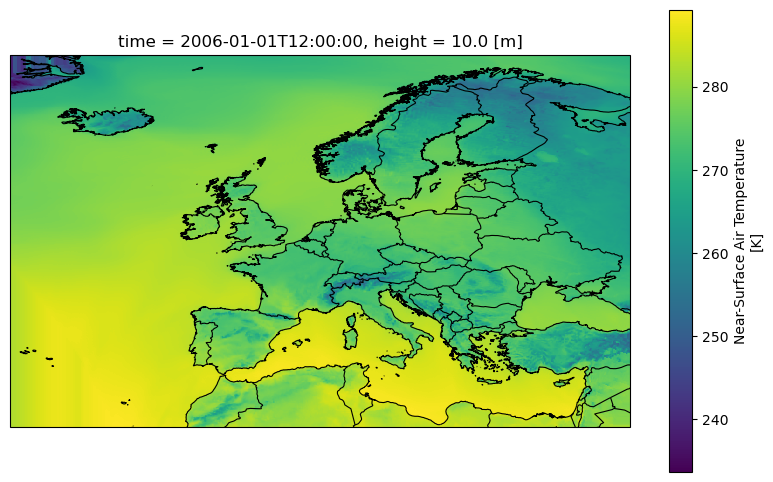

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
data = sel_extent(
    xr.open_dataset(
        Path.cwd() / f"{sorted(path_tas_cnrm.glob('*.nc'))[0].stem}_con.nc"
    ).tas.isel(time=0),
    extent=EXTENT_BC,
)
data.ffill(dim="lat").ffill(dim="lon").bfill(dim="lat").bfill(dim="lon").plot(
    ax=ax, transform=ccrs.PlateCarree()
)
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

In [ ]:
ds_tas_cnrm_regridded = xr.open_zarr(
    "/landclim_nobackup/yhaddad/clim2energy-ch/cordex_processed/CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/regridded/3hr/tas.zarr",
    chunks="auto",
).sel(time="2006")
ds_tas_cnrm_regridded

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 2920, lat: 507, lon: 1096)
Coordinates:
    height   (time) float64 23kB dask.array<chunksize=(2920,), meta=np.ndarray>
  * lat      (lat) float64 4kB 21.95 22.05 22.15 22.25 ... 72.35 72.45 72.55
  * lon      (lon) float64 9kB -44.55 -44.45 -44.35 -44.25 ... 64.75 64.85 64.95
  * time     (time) datetime64[ns] 23kB 2006-01-01 ... 2006-12-31T21:00:00
Data variables:
    tas      (time, lat, lon) float32 6GB dask.array<chunksize=(2920, 20, 20), meta=np.ndarray>
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...

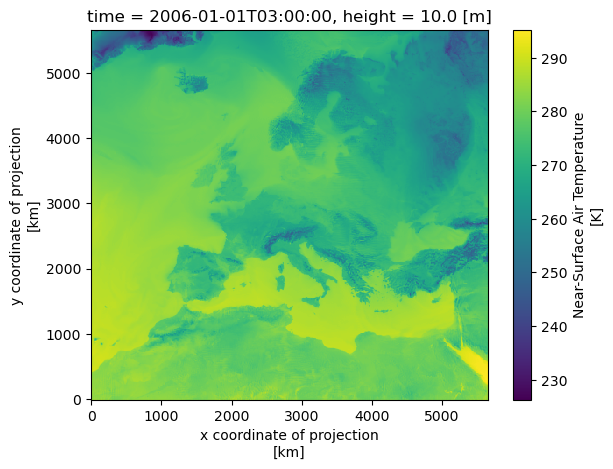

In [43]:
ds_tas_cnrm.tas.isel(time=0).plot()

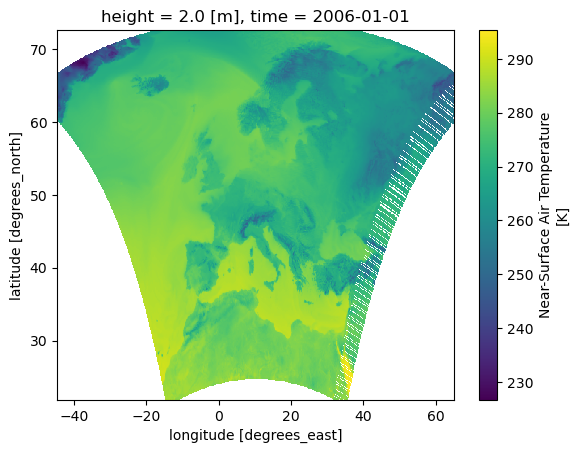

In [44]:
ds_tas_cnrm_regridded.tas.isel(time=0).plot()

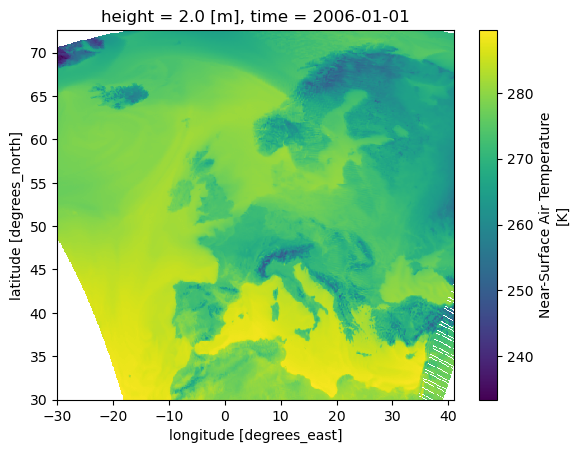

In [45]:
sel_extent(ds_tas_cnrm_regridded.tas.isel(time=0), extent=EXTENT_BC).plot()

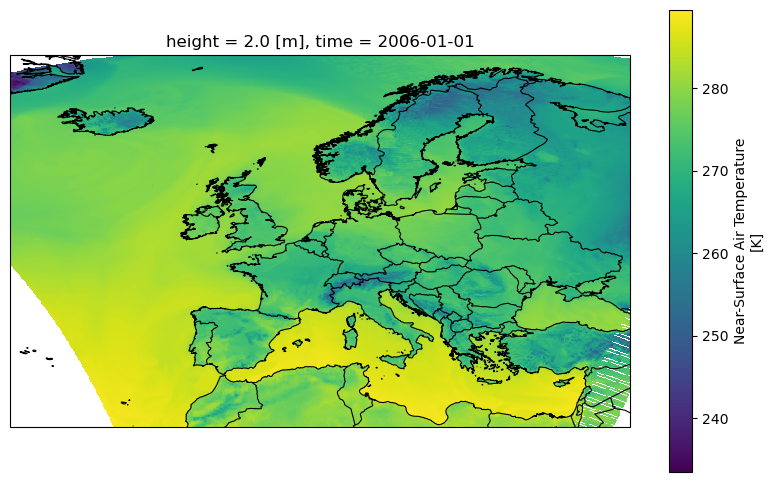

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
sel_extent(ds_tas_cnrm_regridded.tas.isel(time=0), extent=EXTENT_BC).plot(
    ax=ax, transform=ccrs.PlateCarree()
)
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

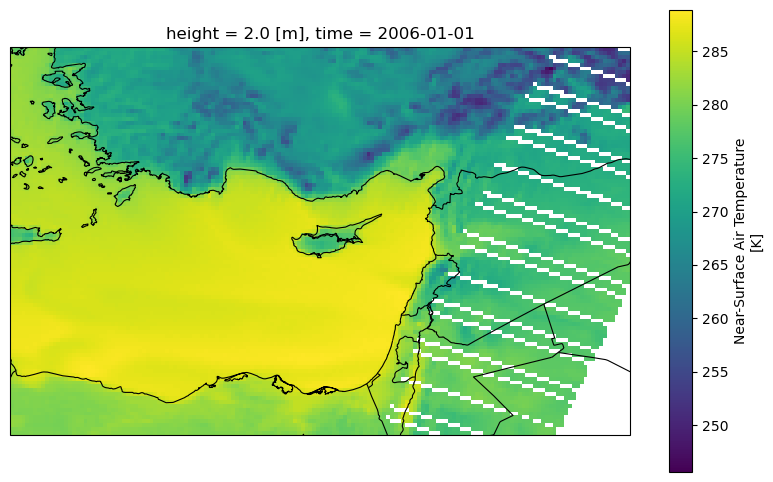

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
sel_extent(
    ds_tas_cnrm_regridded.tas.isel(time=0),
    extent={"lat_min": 30, "lat_max": 40, "lon_min": 25, "lon_max": 41},
).plot(ax=ax, transform=ccrs.PlateCarree())
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

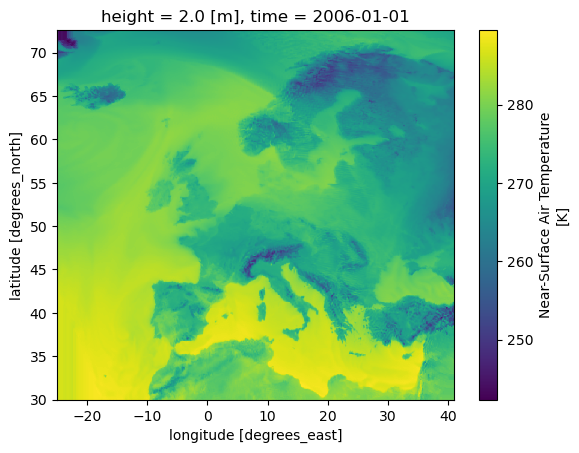

In [ ]:
sel_extent(ds_tas_cnrm_regridded.tas.isel(time=0), extent=EXTENT_BC).ffill(
    dim="lat"
).ffill(dim="lon").bfill(dim="lat").bfill(dim="lon").plot()

# MOHC

In [ ]:
path_tas_mohc = Path(
    "/net/atmos/data/cordex/EUR-11/rcp85/3hr/tas/MOHC/CNRM-CERFACS-CNRM-CM5/MOHC-HadREM3-GA7-05/r1i1p1/"
)
ds_tas_mohc = xr.open_dataset(sorted(path_tas_mohc.glob("*.nc"))[0], chunks="auto")

In [5]:
ds_tas_mohc

<xarray.Dataset> Size: 2GB
Dimensions:                     (rlat: 412, rlon: 424, bnds: 2, time: 2919,
                                 vertices: 4)
Coordinates:
    height                      float64 8B ...
    latitude                    (rlat, rlon) float64 1MB dask.array<chunksize=(412, 424), meta=np.ndarray>
    longitude                   (rlat, rlon) float64 1MB dask.array<chunksize=(412, 424), meta=np.ndarray>
  * rlat                        (rlat) float64 3kB -23.38 -23.26 ... 21.72 21.83
  * rlon                        (rlon) float64 3kB -28.38 -28.27 ... 18.04 18.15
  * time                        (time) datetime64[ns] 23kB 2006-01-01T03:00:0...
Dimensions without coordinates: bnds, vertices
Data variables:
    rlat_bnds                   (rlat, bnds) float64 7kB dask.array<chunksize=(412, 2), meta=np.ndarray>
    rlon_bnds                   (rlon, bnds) float64 7kB dask.array<chunksize=(424, 2), meta=np.ndarray>
    rotated_latitude_longitude  int32 4B ...
    tas                         (time, rlat, rlon) float32 2GB dask.array<chunksize=(192, 412, 424), meta=np.ndarray>
    vertices_latitude           (rlat, rlon, vertices) float64 6MB dask.array<chunksize=(412, 424, 4), meta=np.ndarray>
    vertices_longitude          (rlat, rlon, vertices) float64 6MB dask.array<chunksize=(412, 424, 4), meta=np.ndarray>
Attributes: (12/22)
    model_id:                       MOHC-HadREM3-GA7-05
    driving_experiment_name:        rcp85
    creation_date:                  2021-01-11T11:26:45Z
    project_id:                     CORDEX
    experiment:                     rcp85 run using  CNRM-CERFACS-CNRM-CM5 as...
    institution:                    MetOffice, Hadley Centre, UK
    ...                             ...
    driving_model_id:               CNRM-CERFACS-CNRM-CM5
    tracking_id:                    hdl:21.14103/51e7933a-a1fd-4a26-9f00-a953...
    institute_id:                   MOHC
    frequency:                      3hr
    driving_experiment_comment:     Known issue correction: this simulation (...
    initial_conditions:             This experiment has been initialised usin...

In [ ]:
cdo_remap(
    str(sorted(path_tas_mohc.glob("*.nc"))[0]),
    str(Path.cwd() / sorted(path_tas_mohc.glob("*.nc"))[0].name),
    "bilinear",
    path_data_processed / "climate_grids" / "grid_EUR11_lonlat_griddes.txt",
)

cdo    remapcon: YAC first order conservative weights from curvilinear (424x412) to lonlat (1096x507) grid


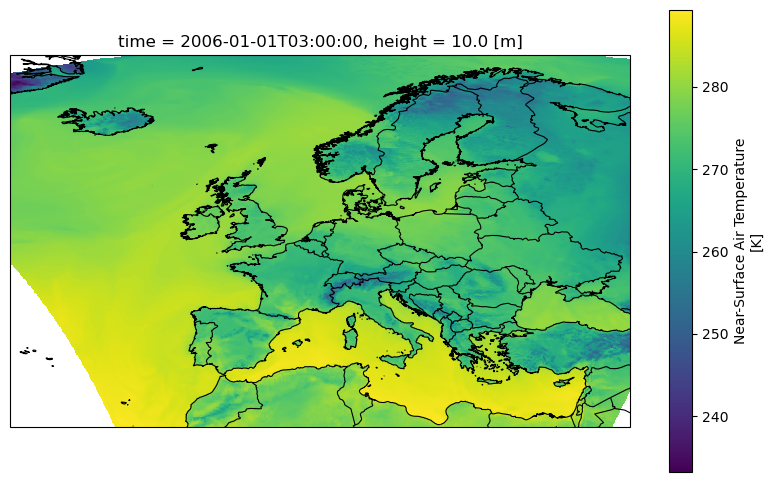

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
data = sel_extent(
    xr.open_dataset(Path.cwd() / sorted(path_tas_mohc.glob("*.nc"))[0].name).tas.isel(
        time=0
    ),
    extent=EXTENT_BC,
)
data.plot(ax=ax, transform=ccrs.PlateCarree())
ax.coastlines(resolution="10m", linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.8)

In [ ]:
ds_tas_mohc_regridded = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85/regridded/3hr/tas.zarr",
    chunks="auto",
)
ds_tas_mohc_regridded

<xarray.Dataset> Size: 945GB
Dimensions:  (lat: 507, lon: 1096, time: 425209)
Coordinates:
    height   float64 8B ...
  * lat      (lat) float64 4kB 21.95 22.05 22.15 22.25 ... 72.35 72.45 72.55
  * lon      (lon) float64 9kB -44.55 -44.45 -44.35 -44.25 ... 64.75 64.85 64.95
  * time     (time) object 3MB 1951-12-01 00:00:00 ... 2099-12-20 00:00:00
Data variables:
    tas      (time, lat, lon) float32 945GB dask.array<chunksize=(425209, 20, 20), meta=np.ndarray>
Attributes: (12/24)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Conventions:                    CF-1.4
    NCO:                            4.7.3
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    model_id:                       MOHC-HadREM3-GA7-05
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v1
    references:                     https://www.metoffice.gov.uk/climate-guid...
    tracking_id:                    hdl:21.14103/20578ea9-f07b-474b-9103-ca77...

In [ ]:
ds_tas_mohc_regridded = xr.open_zarr(
    "/landclim/yhaddad/clim2energy-ch/cordex_processed/MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85/regridded/3hr/rsds.zarr",
    chunks="auto",
)
ds_tas_mohc_regridded

<xarray.Dataset> Size: 1TB
Dimensions:  (lat: 507, lon: 1096, time: 449920)
Coordinates:
  * lat      (lat) float64 4kB 21.95 22.05 22.15 22.25 ... 72.35 72.45 72.55
  * lon      (lon) float64 9kB -44.55 -44.45 -44.35 -44.25 ... 64.75 64.85 64.95
  * time     (time) datetime64[ns] 4MB 1951-12-01T01:30:00 ... 2100-12-30T22:...
Data variables:
    rsds     (time, lat, lon) float32 1TB dask.array<chunksize=(449920, 20, 20), meta=np.ndarray>
Attributes: (12/25)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Conventions:                    CF-1.4
    c3s_disclaimer:                 This data has been produced in the contex...
    contact:                        erasmo.buonomo@metoffice.gov.uk
    ...                             ...
    model_id:                       MOHC-HadREM3-GA7-05
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     https://www.metoffice.gov.uk/climate-guid...
    tracking_id:                    hdl:21.14103/4eac85db-8b54-4563-88c9-20d9...

In [ ]:
# Check if the time dimension is sorted
is_sorted = (
    ds_tas_mohc_regridded.time.values == np.sort(ds_tas_mohc_regridded.time.values)
).all()
print("Time dimension is sorted:", is_sorted)

# Check if the time dimension is unique
is_unique = len(np.unique(ds_tas_mohc_regridded.time.values)) == len(
    ds_tas_mohc_regridded.time.values
)
print("Time dimension is unique:", is_unique)

Time dimension is sorted: True
Time dimension is unique: True


In [19]:
# Find indices where the time values are not sorted
time_values = ds_tas_mohc_regridded.time.values
unsorted_indices = np.where(time_values[:-1] > time_values[1:])[0]
print("Indices where time is unsorted:", unsorted_indices)
print("Unsorted time values:")
for idx in unsorted_indices:
    print(time_values[idx], ">", time_values[idx + 1])

Indices where time is unsorted: []
Unsorted time values:


In [20]:
# Find non-unique time values in ds_tas_mohc_regridded
unique_times, counts = np.unique(time_values, return_counts=True)
non_unique_times = unique_times[counts > 1]
print("Non-unique time values:", non_unique_times)

Non-unique time values: []


In [ ]:
years_in_time = np.unique(pd.to_datetime(time_values).year)
print(years_in_time)

[1951 1952 1953 1954 1955 1956 1957 1958 1959 1960 1961 1962 1963 1964
 1965 1966 1967 1968 1969 1970 1971 1972 1973 1974 1975 1976 1977 1978
 1979 1980 1981 1982 1983 1984 1985 1986 1987 1988 1989 1990 1991 1992
 1993 1994 1995 1996 1997 1998 1999 2000 2001 2002 2003 2004 2005 2006
 2007 2008 2009 2010 2011 2012 2013 2014 2015 2016 2017 2018 2019 2020
 2021 2022 2023 2024 2025 2026 2027 2028 2029 2030 2031 2032 2033 2034
 2035 2036 2037 2038 2039 2040 2041 2042 2043 2044 2045 2046 2047 2048
 2049 2050 2051 2052 2053 2054 2055 2056 2057 2058 2059 2060 2061 2062
 2063 2064 2065 2066 2067 2068 2069 2070 2071 2072 2073 2074 2075 2076
 2077 2078 2079 2080 2081 2082 2083 2084 2085 2086 2087 2088 2089 2090
 2091 2092 2093 2094 2095 2096 2097 2098 2099 2100]
Differences between consecutive years: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 

In [10]:
len(non_unique_times)

14599

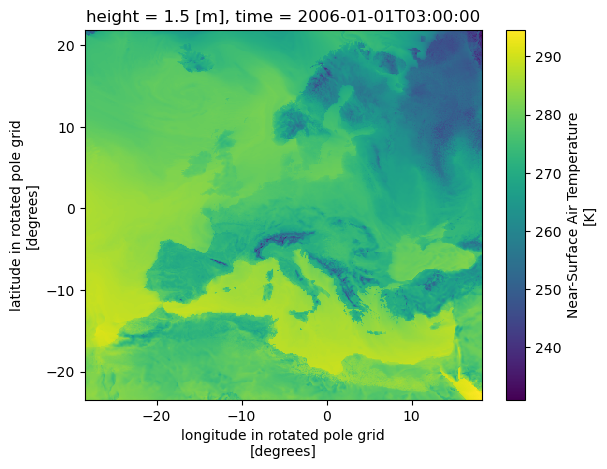

In [13]:
ds_tas_mohc.tas.isel(time=0).plot()

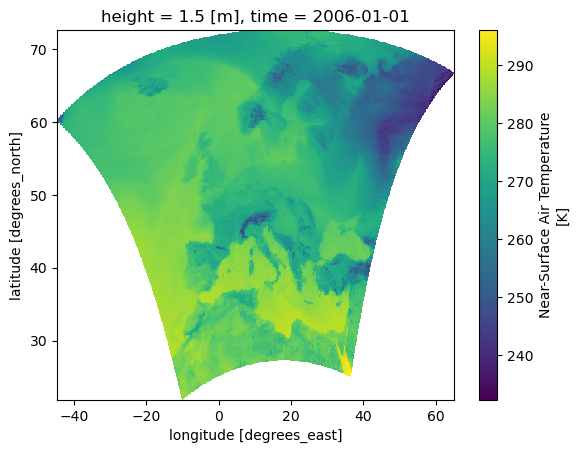

In [14]:
ds_tas_mohc_regridded.tas.isel(time=0).plot()

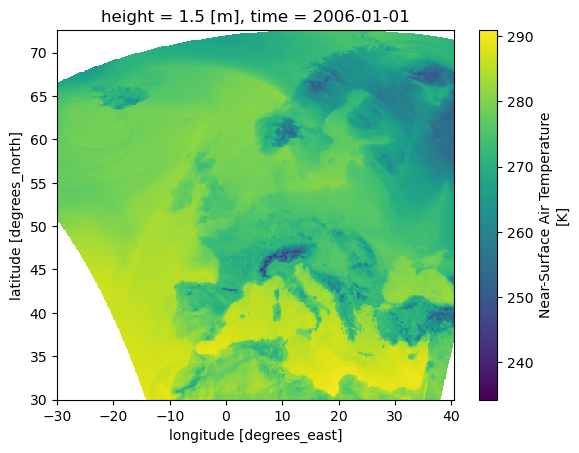

In [20]:
sel_extent(ds_tas_mohc_regridded.tas.isel(time=0), extent=EXTENT_BC).plot()

/tmp/ipykernel_41971/2473339090.py:2: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  gdf_world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_41971/2473339090.py:8: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf_iceland_buffer['geometry'] = gdf_iceland_buffer.geometry.buffer(buffer_distance_deg)


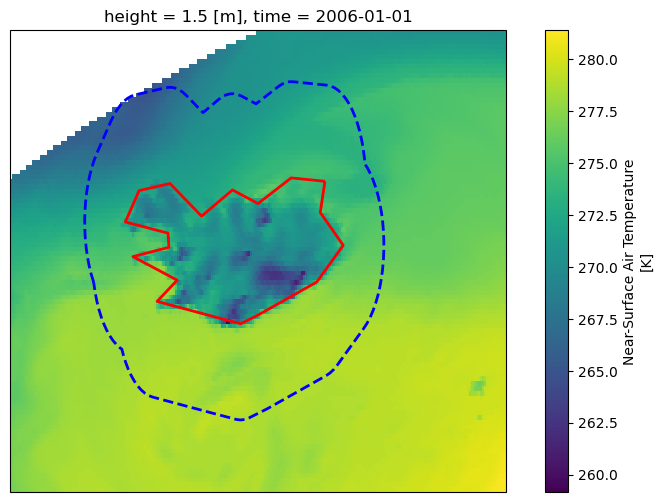

In [ ]:
# Get Iceland geometry from naturalearth_lowres
gdf_world = gpd.read_file(gpd.datasets.get_path("naturalearth_lowres"))
gdf_iceland = gdf_world[gdf_world.name == "Iceland"]

# Buffer the Iceland geometry by 100km (0.9 degrees is ~100km at this latitude)
buffer_distance_deg = 2
gdf_iceland_buffer = gdf_iceland.copy()
gdf_iceland_buffer["geometry"] = gdf_iceland_buffer.geometry.buffer(buffer_distance_deg)

fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"projection": ccrs.PlateCarree()})
gdf_iceland.boundary.plot(
    ax=ax, edgecolor="red", linewidth=2, transform=ccrs.PlateCarree(), label="Iceland"
)
gdf_iceland_buffer.boundary.plot(
    ax=ax,
    edgecolor="blue",
    linewidth=2,
    linestyle="--",
    transform=ccrs.PlateCarree(),
    label="100km buffer",
)
sel_extent(
    ds_tas_mohc_regridded.tas.isel(time=0),
    extent={"lat_min": 59.9689, "lat_max": 69.5833, "lon_min": -30, "lon_max": -5.5734},
).plot(ax=ax, transform=ccrs.PlateCarree())

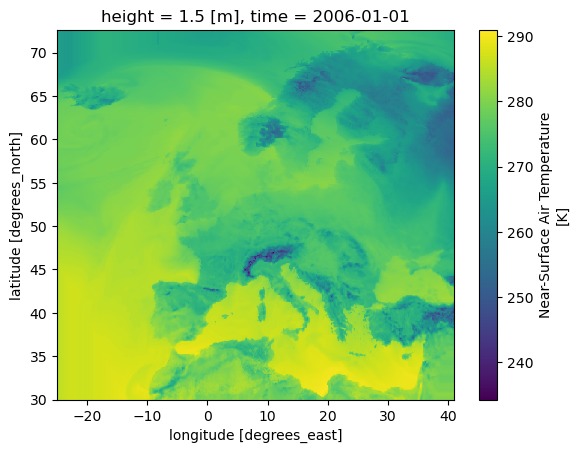

In [ ]:
sel_extent(ds_tas_mohc_regridded.tas.isel(time=0), extent=EXTENT_BC).ffill(
    dim="lat"
).ffill(dim="lon").bfill(dim="lat").bfill(dim="lon").plot()

# MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1

In [54]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1"
climate_scenario = "rcp85"
regridded_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [ ]:
temp_resolution = ["3hr", "day"]

for res in temp_resolution:
    for var in regridded_dir.glob(f"{res}/*.zarr"):
        print(f"Processing {var.name} for {res} resolution")
        ds = xr.open_zarr(var, chunks="auto")
        print("\tFirst time step:", ds.time.values[0])
        print("\tLast time step:", ds.time.values[-1])

Processing tas.zarr for 3hr resolution
	First time step: 1951-12-01 00:00:00
	Last time step: 2099-12-20 00:00:00
Processing hurs.zarr for 3hr resolution
	First time step: 1951-12-01 00:00:00
	Last time step: 2099-12-20 00:00:00
Processing rsds.zarr for 3hr resolution
	First time step: 1951-12-01 01:30:00
	Last time step: 2099-12-19 22:30:00
Processing sfcWind.zarr for 3hr resolution
	First time step: 1951-12-01 00:00:00
	Last time step: 2099-12-20 00:00:00
Processing psl.zarr for 3hr resolution
	First time step: 1951-12-01 00:00:00
	Last time step: 2099-12-20 00:00:00
Processing pr.zarr for day resolution
	First time step: 1951-12-01 12:00:00
	Last time step: 2099-12-19 12:00:00
Processing mrro.zarr for day resolution
	First time step: 1951-12-01 12:00:00
	Last time step: 2099-12-19 12:00:00
Processing clt.zarr for day resolution
	First time step: 1951-12-01 12:00:00
	Last time step: 2099-12-19 12:00:00


In [62]:
ds = xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto").convert_calendar("gregorian", dim="time", align_on="year")

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/core/indexing.py:1593: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]


In [65]:
# Find the expected time range based on the first and last time in ds
expected_times = pd.date_range(start=ds.time.values[0], end=ds.time.values[-1], freq="3H")

# Find missing timesteps
missing_times = expected_times.difference(ds.time.values)
print(f"Number of missing timesteps: {len(missing_times)}")

# Reindex ds to include all expected times, filling missing values with NaN
ds_filled = ds.reindex(time=expected_times)

Number of missing timesteps: 7400


/tmp/ipykernel_10330/1110761227.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  expected_times = pd.date_range(start=ds.time.values[0], end=ds.time.values[-1], freq="3H")
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/core/indexing.py:1593: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/dask/array/core.py:4836: PerformanceWarning: Increasing number of chunks by factor of 26
  result = blockwise(


In [69]:
ds_interp = ds_filled.interpolate_na(
    dim="time",
    method="linear",  # or "cubic" for smoother transitions
    fill_value="extrapolate"  # optional; only use if needed at boundaries
)

In [77]:
ds_interp.sel(time="1991").isel(time=0).tas.plot()

KeyboardInterrupt: 

In [ ]:
# Convert ds.time to a standard (proleptic) Gregorian calendar using cftime
if hasattr(ds.time, 'encoding') and ds.time.encoding.get('calendar', None) not in [None, 'proleptic_gregorian', 'standard', 'gregorian']:
    ds['time'] = xr.cftime_range(
        start=str(ds.time.values[0]),
        periods=ds.time.size,
        freq=pd.infer_freq(pd.to_datetime(ds.time.values))
    ).to_datetimeindex()
else:
    ds['time'] = pd.to_datetime(ds.time.values)

# MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1

In [44]:
climate_model_chain = "MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

regridded_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [ ]:
temp_resolution = ["3hr", "day"]

for res in temp_resolution:
    for var in regridded_dir.glob(f"{res}/*.zarr"):
        print(f"Processing {var.name} for {res} resolution")
        ds = xr.open_zarr(var, chunks="auto")
        print("\tFirst time step:", ds.time.values[0])
        print("\tLast time step:", ds.time.values[-1])

Processing tas.zarr for 3hr resolution
	First time step: 1951-12-01T00:00:00.000000000
	Last time step: 2100-12-31T00:00:00.000000000
Processing hurs.zarr for 3hr resolution
	First time step: 1951-12-01T00:00:00.000000000
	Last time step: 2100-12-31T00:00:00.000000000
Processing rsds.zarr for 3hr resolution
	First time step: 1951-12-01T01:30:00.000000000
	Last time step: 2100-12-30T22:30:00.000000000
Processing sfcWind.zarr for 3hr resolution
	First time step: 1951-12-01T00:00:00.000000000
	Last time step: 2100-12-31T00:00:00.000000000
Processing psl.zarr for 3hr resolution
	First time step: 1951-12-01T00:00:00.000000000
	Last time step: 2100-12-31T00:00:00.000000000
Processing pr.zarr for day resolution
	First time step: 1951-12-01T12:00:00.000000000
	Last time step: 2100-12-30T12:00:00.000000000
Processing mrro.zarr for day resolution
	First time step: 1951-12-01T12:00:00.000000000
	Last time step: 2100-12-30T12:00:00.000000000
Processing clt.zarr for day resolution
	First time step:

In [23]:
ds = xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto")
ds.sel(time=slice("1991", "2020"))

<xarray.Dataset> Size: 195GB
Dimensions:  (lat: 507, lon: 1096, time: 87599)
Coordinates:
    height   float64 8B ...
  * lat      (lat) float64 4kB 21.95 22.05 22.15 22.25 ... 72.35 72.45 72.55
  * lon      (lon) float64 9kB -44.55 -44.45 -44.35 -44.25 ... 64.75 64.85 64.95
  * time     (time) datetime64[ns] 701kB 1991-01-01 ... 2020-12-31T21:00:00
Data variables:
    tas      (time, lat, lon) float32 195GB dask.array<chunksize=(87599, 20, 20), meta=np.ndarray>
Attributes: (12/25)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Conventions:                    CF-1.4
    c3s_disclaimer:                 This data has been produced in the contex...
    contact:                        erasmo.buonomo@metoffice.gov.uk
    ...                             ...
    model_id:                       MOHC-HadREM3-GA7-05
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     https://www.metoffice.gov.uk/climate-guid...
    tracking_id:                    hdl:21.14103/2067855c-322a-44b3-9e5b-d75d...

In [46]:
xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto").time.encoding.get("calendar")

'gregorian'

In [ ]:
var = ds["tas"].isel(time=0)

# Check for NaNs on each border
has_nan = (
    var.isel(lat=0).isnull().any() |
    var.isel(lat=-1).isnull().any() |
    var.isel(lon=0).isnull().any() |
    var.isel(lon=-1).isnull().any()
).compute().item()

# MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1

In [7]:
climate_model_chain = "MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1"
climate_scenario = "rcp85"

regridded_dir = (
    path_data_processed
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [8]:
temp_resolution = ["3hr", "day"]

for res in temp_resolution:
    for var in regridded_dir.glob(f"{res}/*.zarr"):
        print(f"Processing {var.name} for {res} resolution")
        ds = xr.open_zarr(var, chunks="auto")
        print("\tFirst time step:", ds.time.values[0])
        print("\tLast time step:", ds.time.values[-1])

Processing tas.zarr for 3hr resolution
	First time step: 1951-12-01T00:00:00.000000000
	Last time step: 2100-12-31T21:00:00.000000000
Processing hurs.zarr for 3hr resolution
	First time step: 1951-12-01T00:00:00.000000000
	Last time step: 2100-12-31T21:00:00.000000000
Processing rsds.zarr for 3hr resolution
	First time step: 1951-12-01T01:30:00.000000000
	Last time step: 2100-12-31T22:30:00.000000000
Processing sfcWind.zarr for 3hr resolution
	First time step: 1951-12-01T00:00:00.000000000
	Last time step: 2100-12-31T21:00:00.000000000
Processing psl.zarr for 3hr resolution
	First time step: 1951-12-01T00:00:00.000000000
	Last time step: 2100-12-31T21:00:00.000000000
Processing pr.zarr for day resolution
	First time step: 1951-12-01T12:00:00.000000000
	Last time step: 2100-12-31T12:00:00.000000000
Processing mrro.zarr for day resolution
	First time step: 1951-12-01T12:00:00.000000000
	Last time step: 2100-12-31T12:00:00.000000000
Processing clt.zarr for day resolution
	First time step:

In [9]:
ds = xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto")

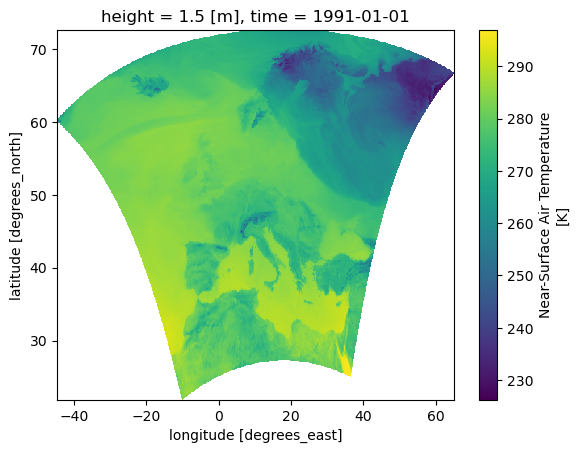

In [10]:
ds.sel(time="1991-01-01T00:00:00").tas.plot()

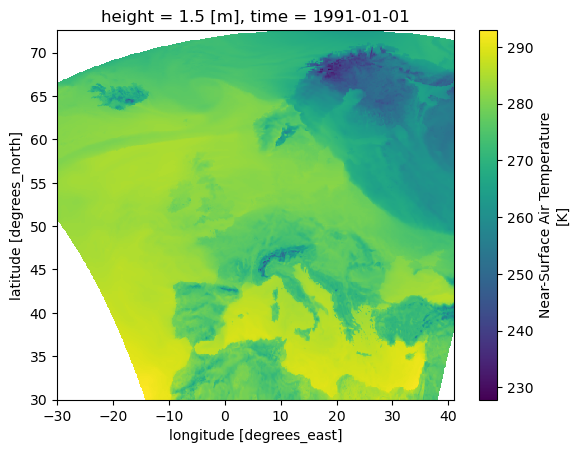

In [11]:
sel_extent(ds.sel(time="1991-01-01T00:00:00").tas, extent=EXTENT_BC).plot()

# CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1

In [7]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp26"

regridded_dir = (
    path_data_temporary
    / "cordex_processed"
    / f"{climate_model_chain}_{climate_scenario}"
    / "regridded"
)

In [43]:
xr.open_zarr(regridded_dir / "3hr" / "tas.zarr", chunks="auto").time.encoding.get("calendar")

'proleptic_gregorian'